<a href="https://colab.research.google.com/github/VANJALI1234/Student_Performance_Prediction_System/blob/main/Student_Performance_Prediction_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Import Libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report


**Step** 1 : **Load** **Dataset**

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/student_performance_dataset_500_records.csv')

In [ ]:
df.head()

,Student_ID,Gender,Age,Study_Hours,Attendance,Previous_Score,Assignments_Completed,Sleep_Hours,Extracurricular_Activities,Internet_Access,Parent_Education,Final_Score,Performance
0,S001,Male,16,6.9,70,54,5,7.9,Yes,No,School,66,Average
1,S002,Male,20,2.6,96,84,9,5.9,No,Yes,Diploma,69,Average
2,S003,Female,18,3.2,68,88,8,5.4,No,Yes,Undergraduate,67,Average
3,S004,Male,21,4.7,62,64,4,7.2,No,Yes,School,53,Average
4,S005,Male,21,2.8,73,45,6,8.5,No,No,Postgraduate,48,Poor


In [ ]:
print(df.shape)

(500, 13)


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  500 non-null    object 
 1   Gender                      500 non-null    object 
 2   Age                         500 non-null    int64  
 3   Study_Hours                 500 non-null    float64
 4   Attendance                  500 non-null    int64  
 5   Previous_Score              500 non-null    int64  
 6   Assignments_Completed       500 non-null    int64  
 7   Sleep_Hours                 500 non-null    float64
 8   Extracurricular_Activities  500 non-null    object 
 9   Internet_Access             500 non-null    object 
 10  Parent_Education            500 non-null    object 
 11  Final_Score                 500 non-null    int64  
 12  Performance                 500 non-null    object 
dtypes: float64(2), int64(5), object(6)


In [ ]:
print(df.describe())

              Age  Study_Hours  Attendance  Previous_Score  \
count  500.000000   500.000000  500.000000      500.000000   
mean    19.094000     5.162600   78.640000       68.600000   
std      1.975086     2.383086   13.389584       15.828616   
min     16.000000     1.100000   55.000000       40.000000   
25%     17.000000     2.900000   68.000000       56.000000   
50%     19.000000     5.200000   79.000000       68.000000   
75%     21.000000     7.300000   90.000000       82.000000   
max     22.000000     9.000000  100.000000       95.000000   

       Assignments_Completed  Sleep_Hours  Final_Score  
count             500.000000   500.000000    500.00000  
mean                6.388000     7.083400     65.22800  
std                 2.331594     1.167918      9.99158  
min                 3.000000     5.000000     34.00000  
25%                 4.000000     6.075000     58.00000  
50%                 6.000000     7.150000     65.00000  
75%                 9.000000     8.100000 

In [ ]:
print(df.isnull().sum())

Student_ID                    0
Gender                        0
Age                           0
Study_Hours                   0
Attendance                    0
Previous_Score                0
Assignments_Completed         0
Sleep_Hours                   0
Extracurricular_Activities    0
Internet_Access               0
Parent_Education              0
Final_Score                   0
Performance                   0
dtype: int64


**Step 2 : Data Cleaning -** **Handle Missing Values**


In [ ]:
df['Study_Hours'] = df['Study_Hours'].fillna(df['Study_Hours'].median())
df['Sleep_Hours'] = df['Sleep_Hours'].fillna(df['Sleep_Hours'].median())


In [ ]:
df.drop('Student_ID',axis=1,inplace=True)

Performance
Average    381
Good        93
Poor        26
Name: count, dtype: int64


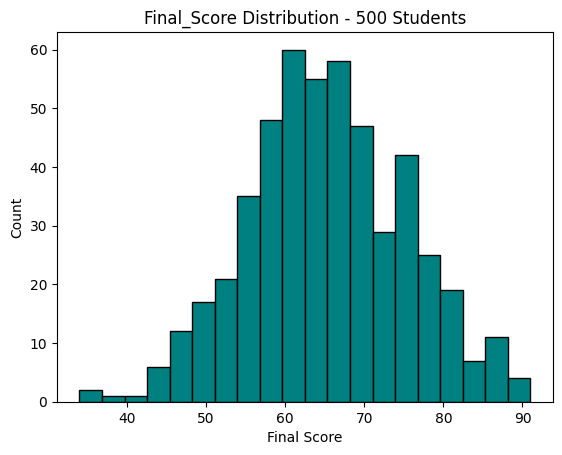

In [ ]:
#  Understand target distribution
print(df['Performance'].value_counts())
plt.hist(df['Final_Score'], bins=20, color='teal', edgecolor='black')
plt.title('Final_Score Distribution - 500 Students')
plt.xlabel('Final Score'); plt.ylabel('Count')
plt.show()

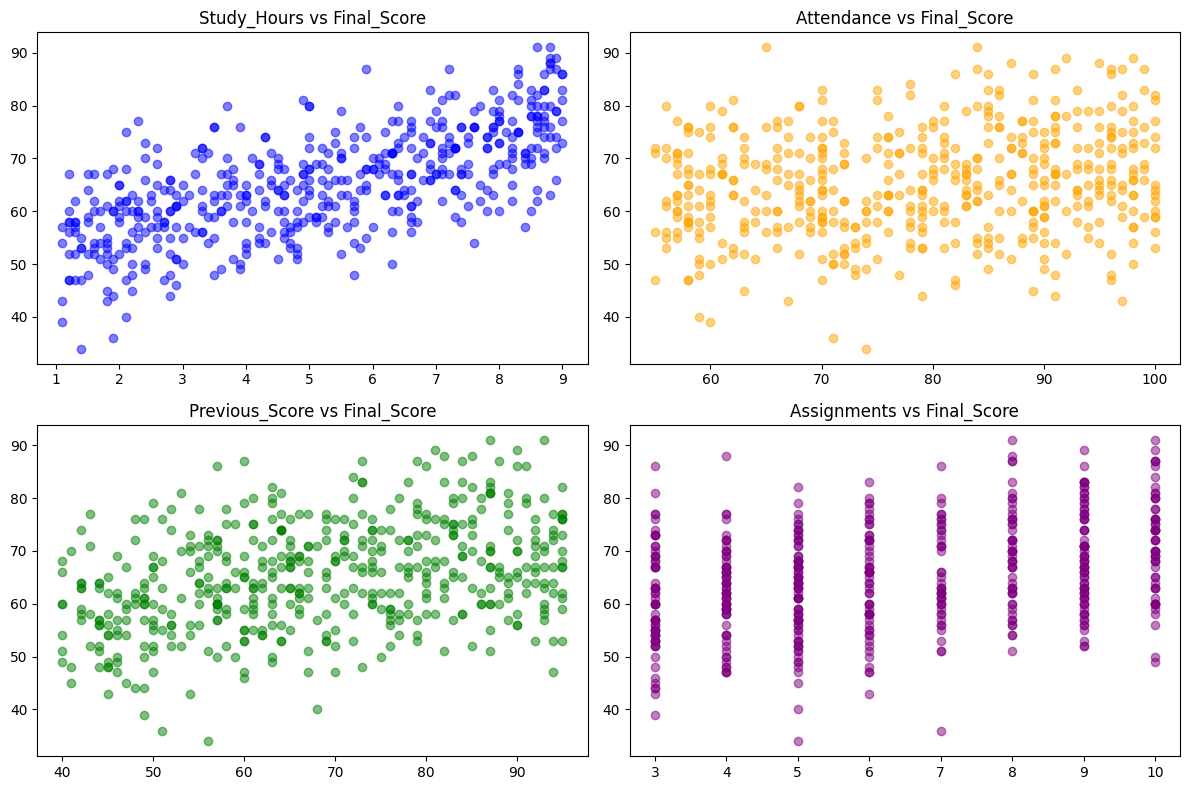

In [ ]:
#EDA - Visualizations For Columns
fig,axes=plt.subplots(2,2,figsize=(12,8))

axes[0,0].scatter(df['Study_Hours'],df['Final_Score'],alpha=0.5,color='blue')
axes[0,0].set_title('Study_Hours vs Final_Score')

axes[0,1].scatter(df['Attendance'],df['Final_Score'],alpha=0.5,color='Orange')
axes[0,1].set_title('Attendance vs Final_Score')

axes[1,0].scatter(df['Previous_Score'],df['Final_Score'],alpha=0.5,color='green')
axes[1,0].set_title('Previous_Score vs Final_Score')

axes[1,1].scatter(df['Assignments_Completed'],df['Final_Score'],alpha=0.5,color='purple')
axes[1,1].set_title('Assignments vs Final_Score')

plt.tight_layout();
plt.show()

/tmp/ipykernel_515/4082841112.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([df[df['Gender']=='Male']['Final_Score'],


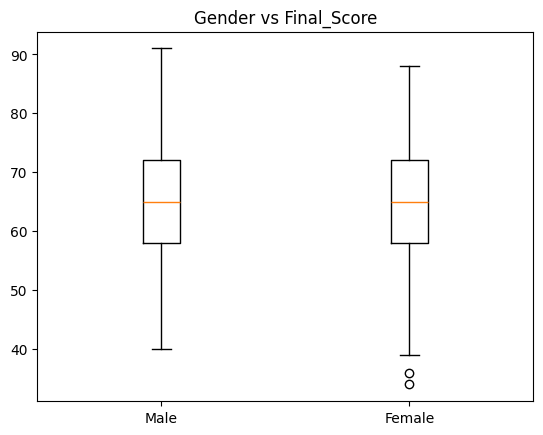

In [ ]:
# Boxplot - Gender, Extracurricular vs Score
plt.boxplot([df[df['Gender']=='Male']['Final_Score'],
             df[df['Gender']=='Female']['Final_Score']], labels=['Male','Female'])
plt.title('Gender vs Final_Score'); plt.show()

Final_Score              1.000000
Study_Hours              0.680975
Previous_Score           0.370543
Assignments_Completed    0.360759
Attendance               0.192742
Sleep_Hours              0.056722
Age                      0.033033
Name: Final_Score, dtype: float64


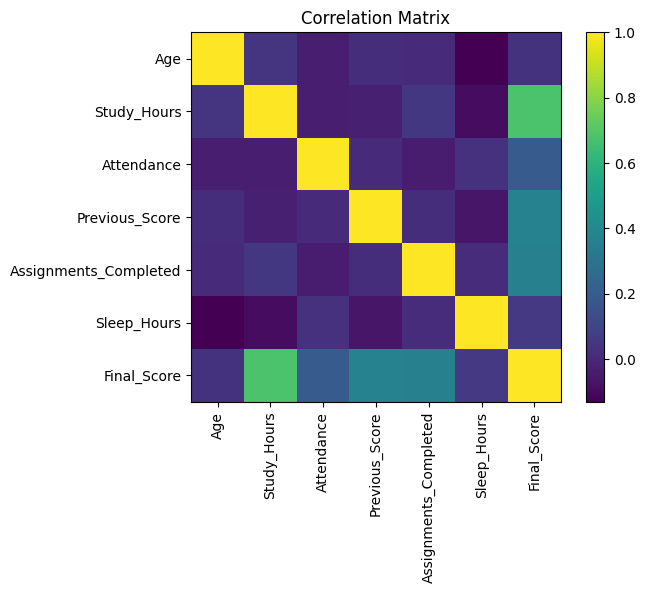

In [ ]:
# 4. Correlation
numeric = df.select_dtypes(include=['int64','float64'])
corr = numeric.corr()
print(corr['Final_Score'].sort_values(ascending=False))

# Heatmap (if seaborn not available, use plt.imshow)
plt.imshow(corr, cmap='viridis')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Correlation Matrix'); plt.colorbar(); plt.show()

In [ ]:
# 5. Feature Selection - For your data
# Most Important will be: Previous_Score, Study_Hours, Attendance, Assignments_Completed
print("Selected Features: Study_Hours, Attendance, Previous_Score, Assignments_Completed, Sleep_Hours, Age")

Selected Features: Study_Hours, Attendance, Previous_Score, Assignments_Completed, Sleep_Hours, Age


WEEK 2


In [ ]:
# Encode categoricals: Gender, Extracurricular_Activities, Internet_Access, Parent_Education, Performance
le = LabelEncoder()
for col in ['Gender','Extracurricular_Activities','Internet_Access','Parent_Education']:
    df[col] = le.fit_transform(df[col])

In [ ]:
# === MODEL 1: REGRESSION (Predict Final_Score) ===
X = df[['Age','Study_Hours','Attendance','Previous_Score','Assignments_Completed','Sleep_Hours','Gender','Extracurricular_Activities','Internet_Access','Parent_Education']]
y_reg = df['Final_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)

In [ ]:
# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
print(f"Linear Regression - R2: {r2_score(y_test, pred_lr):.3f}, MSE: {mean_squared_error(y_test, pred_lr):.2f}")

Linear Regression - R2: 0.794, MSE: 19.14


In [ ]:
# Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train, y_train)
pred_rf = rf_reg.predict(X_test)
print(f"Random Forest Regressor - R2: {r2_score(y_test, pred_rf):.3f}, MSE: {mean_squared_error(y_test, pred_rf):.2f}")

Random Forest Regressor - R2: 0.691, MSE: 28.79


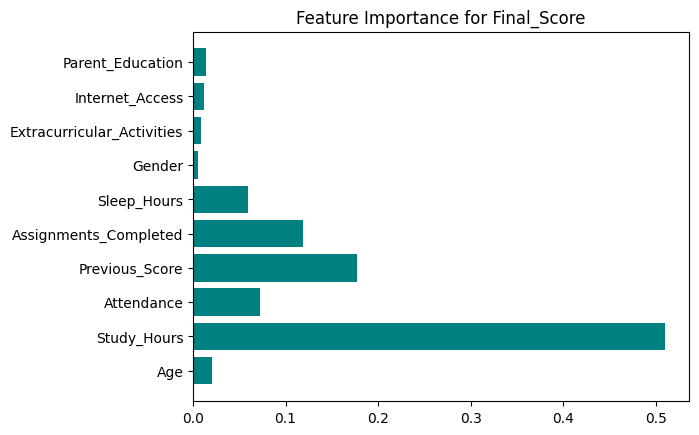

In [ ]:
# Feature Importance
import matplotlib.pyplot as plt
plt.barh(X.columns, rf_reg.feature_importances_, color='teal')
plt.title('Feature Importance for Final_Score'); plt.show()

In [ ]:
# === MODEL 2: CLASSIFICATION (Predict Performance Grade) ===
y_cls = df['Performance'] # Like Low/Medium/High or A/B/C
# Need to encode Performance if it's string
y_cls_encoded = LabelEncoder().fit_transform(y_cls)

X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y_cls_encoded, test_size=0.2, random_state=42)

rf_cls = RandomForestClassifier(n_estimators=100, random_state=42)
rf_cls.fit(X_train2, y_train2)
pred_cls = rf_cls.predict(X_test2)

print(f"Classification Accuracy: {accuracy_score(y_test2, pred_cls)*100:.2f}%")
print(classification_report(y_test2, pred_cls))


Classification Accuracy: 85.00%
              precision    recall  f1-score   support

           0       0.85      0.99      0.91        79
           1       1.00      0.39      0.56        18
           2       0.00      0.00      0.00         3

    accuracy                           0.85       100
   macro avg       0.62      0.46      0.49       100
weighted avg       0.85      0.85      0.82       100



In [ ]:
# === PREDICTION SYSTEM ===
def predict_student(age, study_hours, attendance, prev_score, assignments, sleep, gender, extra, internet, parent_edu):
    # gender: Male=1 Female=0 (check your encoding), use same LabelEncoder mapping
    # For simplicity, assume: Male=1, Female=0, Yes=1 No=0, Parent Education: High=0, Medium=1, Low=2 (check le.classes_)
    input_data = [[age, study_hours, attendance, prev_score, assignments, sleep, gender, extra, internet, parent_edu]]
    score = rf_reg.predict(input_data)[0]
    # Convert score to performance
    if score >= 85: perf = "Excellent"
    elif score >= 70: perf = "Good"
    elif score >= 50: perf = "Average"
    else: perf = "Needs Improvement"
    return round(score,2), perf

# Example
print(predict_student(18, 6.5, 90, 80, 8, 7.5, 1, 1, 1, 0))

# Save model
import pickle
pickle.dump(rf_reg, open('student_final_score_model.pkl','wb'))

(np.float64(79.44), 'Good')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
